# VPPA Risk Lab: a 24/7 data center's virtual PPA in ERCOT

**Question:** a hypothetical data center uses a flat **100 MW, 24 hours a day** in West Texas.
It wants to back that use with clean energy through a **virtual power purchase agreement (VPPA)**.
What does that contract cost, how risky is it, and which kind of project should it buy from?

**How a VPPA works.** The project sells its power into the ERCOT market as usual. Every hour the
buyer and the project settle the difference between the market price and a fixed **strike** price:

$$\text{settlement}_h = (\text{price}_h - \text{strike}) \times \text{MWh}_h$$

Positive means the project pays the buyer; negative means the buyer pays the project.
The buyer receives the renewable energy certificates (RECs) and a partial hedge on power prices.

**Everything here uses public data only** (ERCOT reports via the open-source `gridstatus` library and
ERCOT's public files). The projects are **hypothetical proxies**, not real assets.

| Section | Question |
|---|---|
| 1. Data | What do ERCOT prices and renewable output look like? |
| 2. Proxy projects | What would a 200 MW solar and a 200 MW wind farm produce? |
| 3. Backtest | What would the contract have paid in 2023-2025? |
| 4. Risk decomposition | Price, shape, basis (buyer side) and volume risk, one at a time |
| 5. Monte Carlo | How bad could a bad year be? |
| 6. Portfolio | Solar, wind, a blend, or solar + battery? |
| 7. Hedge effectiveness | Does the VPPA make the power bill steadier, and at what price? |

In [1]:
# Make the project's `vppa` package importable from this notebook folder.
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from IPython.display import Image, display

from vppa import config, data, profiles, settlement, risk, montecarlo, portfolio, plots

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
STRIKE = config.STRIKE          # change this to re-run everything at another strike ($/MWh)
print(f"Hub: {config.HUB} | years: {config.YEARS} | strike: ${STRIKE}/MWh | load: {config.LOAD_MW} MW")

Hub: HB_WEST | years: [2023, 2024, 2025] | strike: $35.0/MWh | load: 100.0 MW


## 1. Data

- **Prices:** hourly real-time settlement point prices at **HB_WEST**, the West Texas trading hub
  (ERCOT report NP6-785-ER, 15-minute prices averaged to hourly).
- **Generation:** ERCOT-wide hourly solar and wind output (ERCOT "Interval Generation by Fuel" files).

Data is downloaded once and cached as parquet in `data/` (run `python scripts/fetch_data.py`).

In [2]:
price = data.load_hub_prices()
system_gen = data.load_system_generation()
print(f"{len(price):,} hourly prices from {price.index.min():%Y-%m-%d} to {price.index.max():%Y-%m-%d}")
price.groupby(price.index.year).describe()[["mean", "50%", "min", "max"]].rename(columns={"50%": "median"})

26,304 hourly prices from 2023-01-01 to 2025-12-31


,mean,median,min,max
hour_start,,,,
2023,49.45,21.84,-31.14,"5,257.57"
2024,27.45,20.02,-31.74,"3,056.64"
2025,32.88,27.34,-30.62,"1,963.41"


**Reading this:** the average price sits well above the median because a handful of scarcity hours
(thousands of $/MWh) pull it up. Prices also go **negative**, when renewables flood the grid.
Both facts drive everything that follows.

## 2. Proxy projects: 200 MW solar and 200 MW wind

We scale ERCOT-wide output down to a 200 MW project using the hourly **capacity factor**
(output ÷ installed capacity). Dividing by installed capacity first matters: ERCOT's solar fleet more
than doubled from 2022 to 2025, and we don't want construction to look like weather.

*Limitation:* a statewide fleet is smoother than any single plant, so this proxy probably
**understates** shape and volume risk.

,solar_mwh,solar_cf,wind_mwh,wind_cf
year,,,,
2023,"350,396.72",0.20,"571,674.13",0.33
2024,"373,043.61",0.21,"571,511.35",0.33
2025,"405,716.71",0.23,"573,314.89",0.33


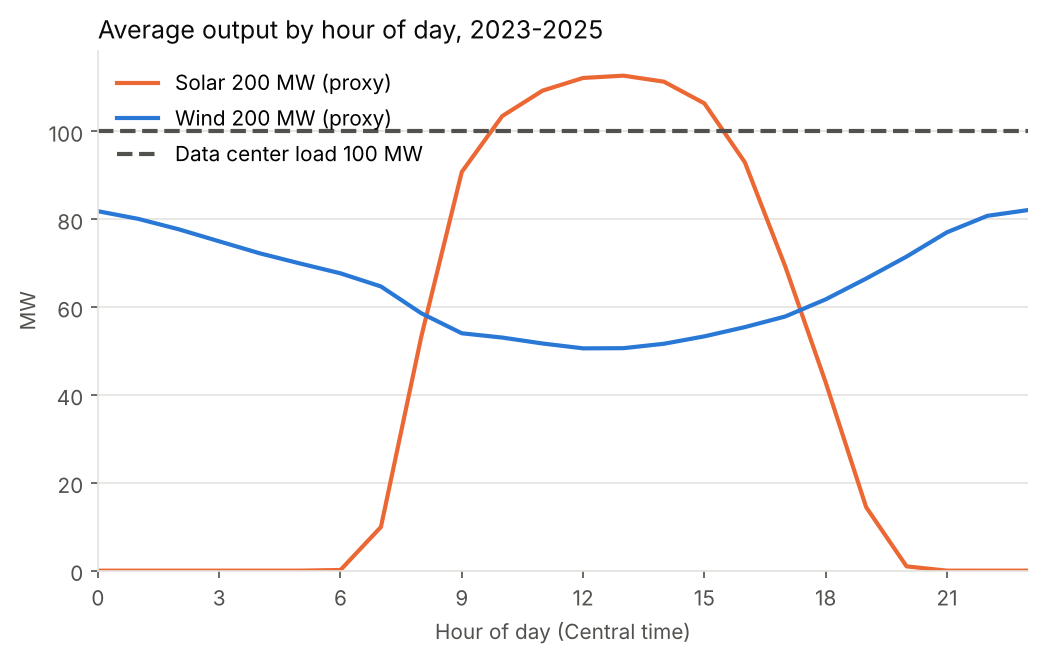

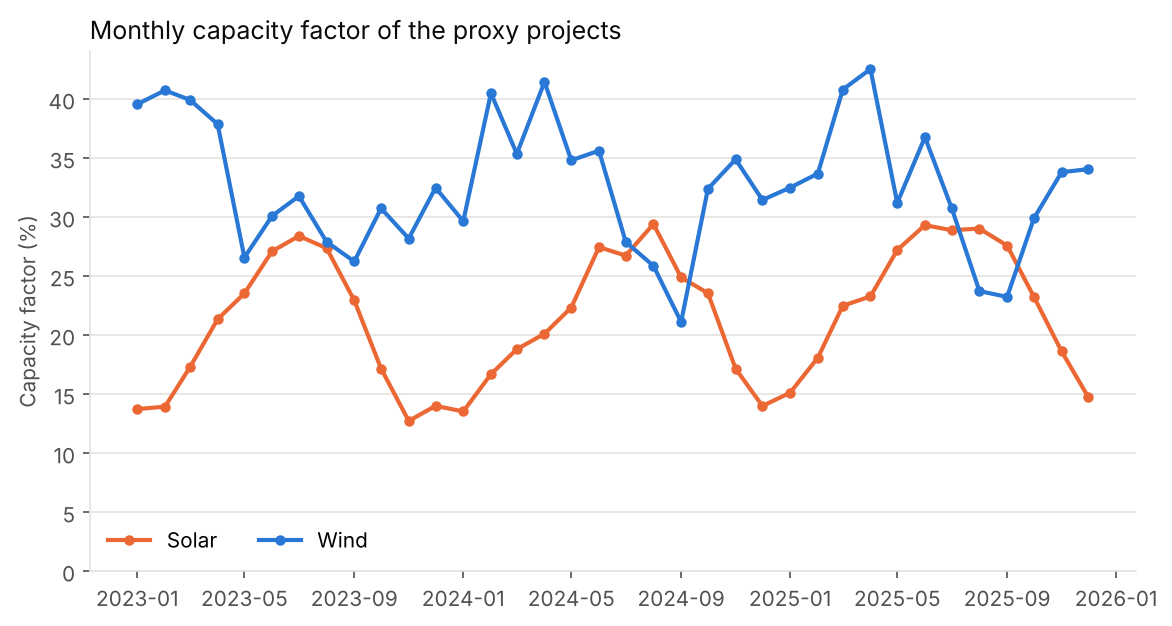

In [3]:
gen = profiles.build_profiles(system_gen)
display(profiles.summarize(gen))
display(Image(plots.plot_average_day(gen)))
display(Image(plots.plot_monthly_capacity_factor(gen)))

Solar and wind have **opposite shapes**: solar is a midday hump, wind is strongest at night.
Their seasons are opposite too: wind peaks in spring, solar in summer.

## 3. Historical backtest at HB_WEST

The **capture price** is the generation-weighted average price: what the project's MWh were actually
worth. When it is below the hub's simple average, the project tends to produce when power is cheap.


SOLAR


,mwh,settlement_$M,hub_avg_price,capture_price,settlement_per_mwh
hour_start,,,,,
2023,"350,396.72",11.08,49.45,66.62,31.62
2024,"373,043.61",-5.41,27.45,20.50,-14.50
2025,"405,716.71",-5.54,32.88,21.34,-13.66



WIND


,mwh,settlement_$M,hub_avg_price,capture_price,settlement_per_mwh
hour_start,,,,,
2023,"571,674.13",-1.14,49.45,33.01,-1.99
2024,"571,511.35",-8.78,27.45,19.64,-15.36
2025,"573,314.89",-5.02,32.88,26.25,-8.75


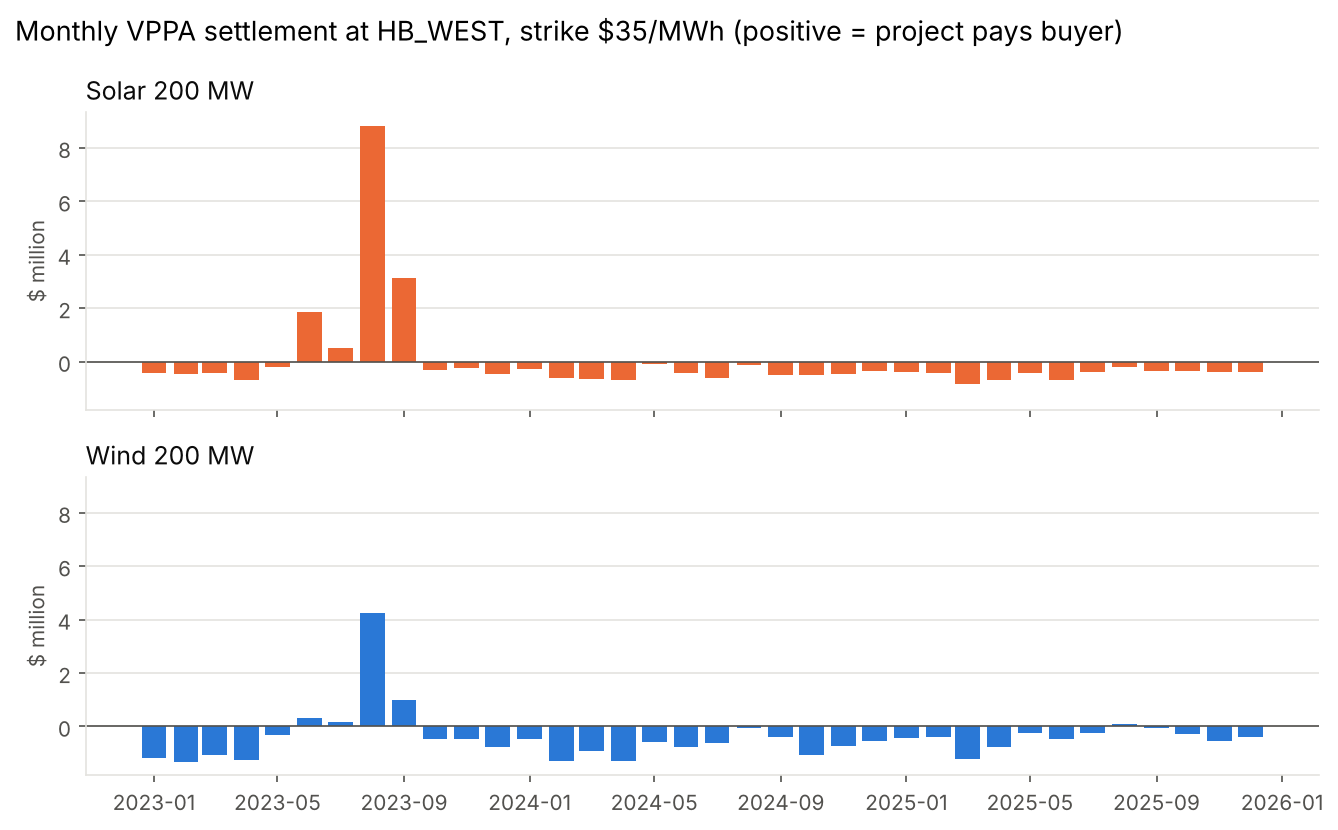

In [4]:
results = settlement.backtest(price, gen, STRIKE)
for name, hourly in results.items():
    annual = settlement.summarize_settlement(hourly, "YS")
    annual.index = annual.index.year
    print(f"\n{name.upper()}")
    display(annual.assign(settlement=lambda d: d.settlement / 1e6)
                  .rename(columns={"settlement": "settlement_$M"}))
display(Image(plots.plot_monthly_settlement(results, STRIKE)))

Negative-price hours and what they cost the buyer:

SOLAR


,negative_hours,mwh_in_negative_hours,settlement_in_negative_hours,share_of_mwh
year,,,,
2023,727,"22,321.46","-845,940.68",0.06
2024,858,"38,735.90","-1,476,689.89",0.10
2025,638,"45,615.09","-1,822,478.05",0.11



WIND


,negative_hours,mwh_in_negative_hours,settlement_in_negative_hours,share_of_mwh
year,,,,
2023,727,"82,345.78","-3,192,175.01",0.14
2024,858,"93,816.63","-3,751,088.47",0.16
2025,638,"65,302.48","-2,659,866.09",0.11


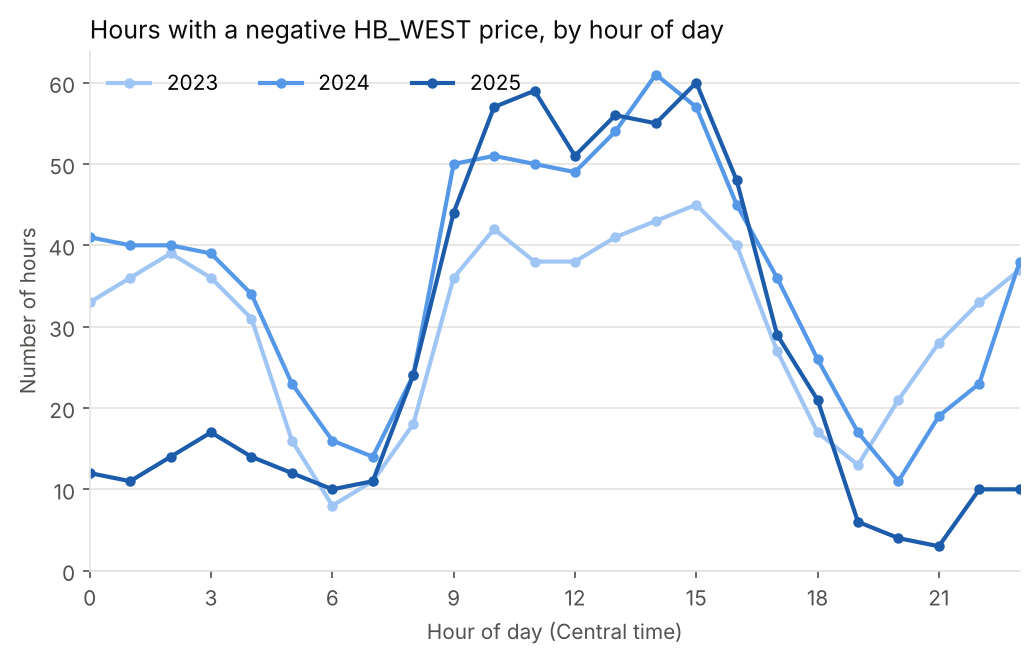

In [5]:
print("Negative-price hours and what they cost the buyer:")
for name, hourly in results.items():
    print(f"\n{name.upper()}")
    display(settlement.negative_price_summary(hourly))
display(Image(plots.plot_negative_price_hours(price)))

**What stands out:** one month (August 2023, a heat wave) dominates the whole solar result, and
negative prices moved from night toward midday as solar grew.

## 4. Risk decomposition

### 4a. Price risk: what if prices are higher or lower?

The buyer is effectively **long** its contract volume: every $1/MWh move in price changes annual
settlement by $1 × annual MWh. But the more important finding is *where* the money comes from.

solar: top 1% price hours (>235 $/MWh) = +14.7M | all other hours = -14.6M | breakeven price move = -0.11 $/MWh
 wind: top 1% price hours (>235 $/MWh) = +8.6M | all other hours = -23.5M | breakeven price move = +8.70 $/MWh


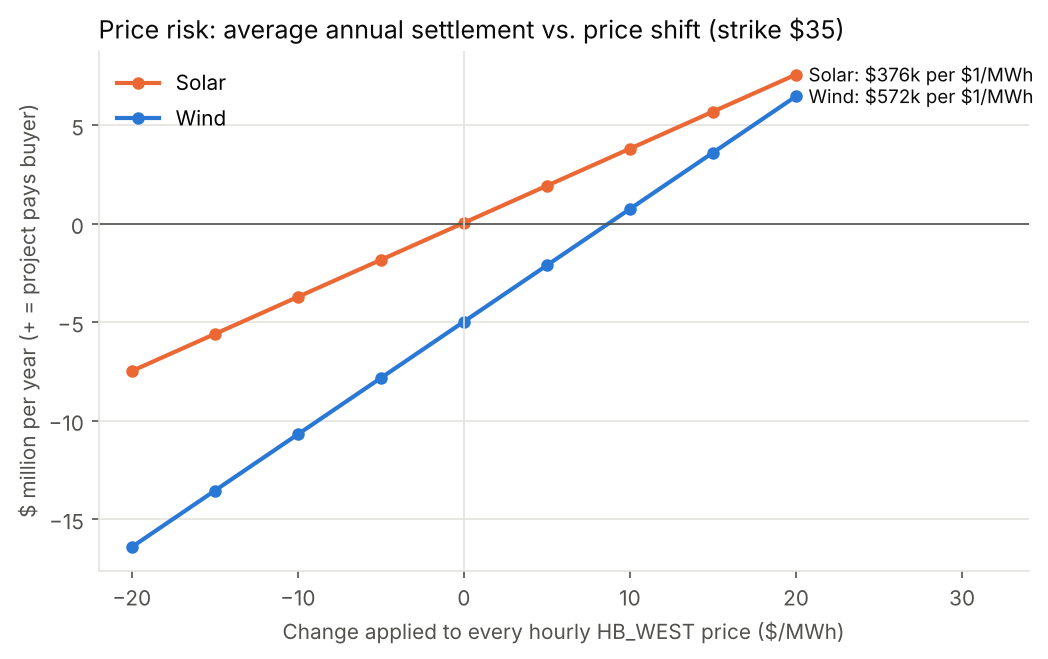

In [6]:
for col in gen.columns:
    tail = risk.tail_concentration(price, gen[col], STRIKE)
    print(f"{col[:-3]:>5}: top 1% price hours (>{tail['price_cutoff']:,.0f} $/MWh) = "
          f"{tail['settlement_in_top_hours'] / 1e6:+.1f}M | all other hours = "
          f"{tail['settlement_in_other_hours'] / 1e6:+.1f}M | breakeven price move = "
          f"{risk.breakeven_price_shift(price, gen[col], STRIKE):+.2f} $/MWh")
display(Image(plots.plot_price_sensitivity(price, gen, STRIKE)))

Price risk lives in the **tails**: a few scarcity hours earn back most of what the other 99% cost.
An average-price view would miss this entirely.

### 4b. Shape risk: is the power made when the data center needs it?

- **Annual matching:** total clean MWh ÷ total MWh used. The usual "100% renewable" claim.
- **Hourly matching:** only clean MWh produced *in the same hour* counts. The 24/7 view.


SOLAR


,annual_volume_match,hourly_match,hours_fully_covered,excess_share,shape_discount_per_mwh
year,,,,,
2023,0.40,0.36,0.20,0.11,-17.18
2024,0.42,0.37,0.22,0.14,6.95
2025,0.46,0.38,0.25,0.17,11.54



WIND


,annual_volume_match,hourly_match,hours_fully_covered,excess_share,shape_discount_per_mwh
year,,,,,
2023,0.65,0.63,0.20,0.04,16.43
2024,0.65,0.62,0.21,0.05,7.80
2025,0.65,0.63,0.19,0.04,6.63


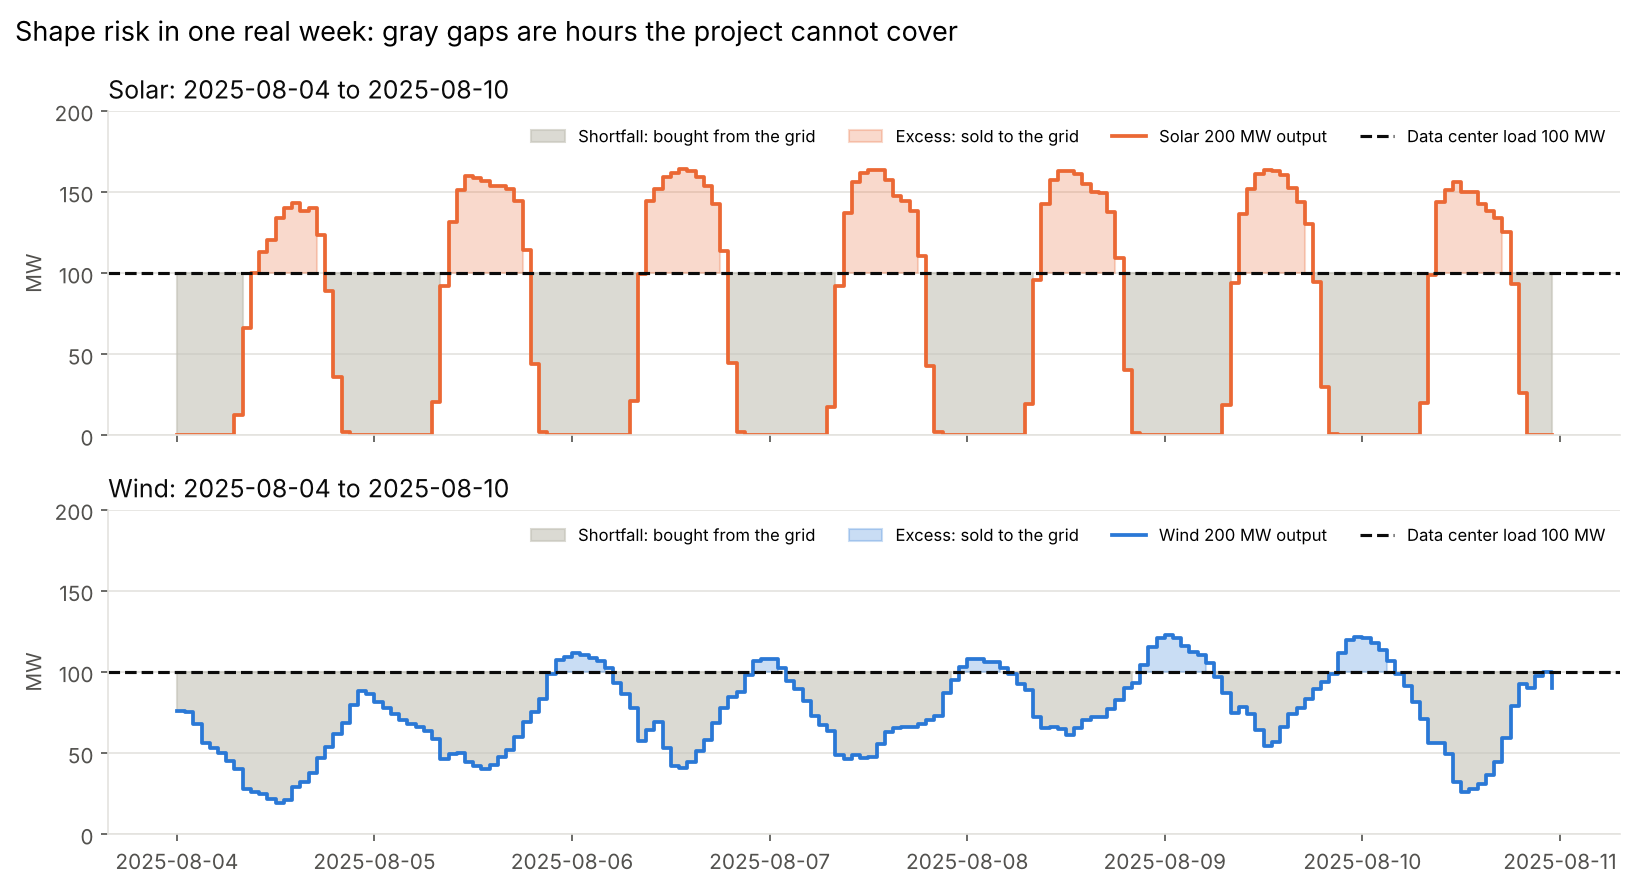

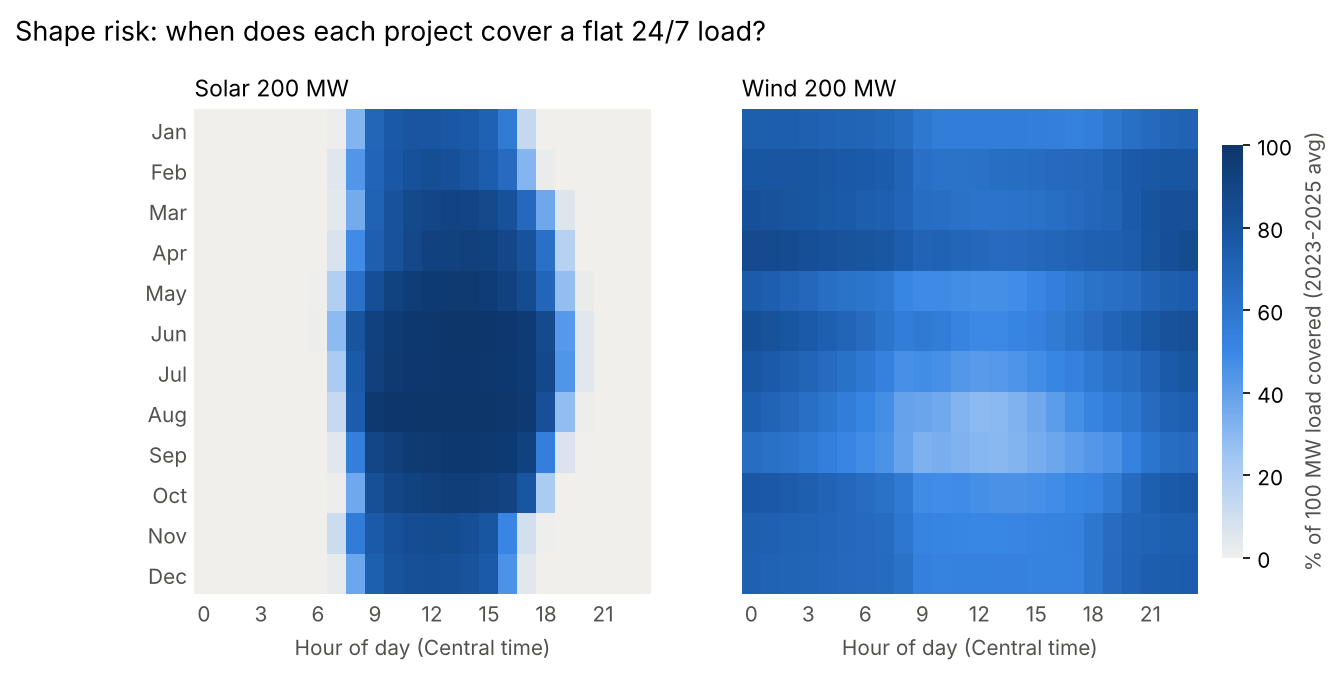

In [7]:
for col in gen.columns:
    print(f"\n{col[:-3].upper()}")
    display(risk.hourly_match(gen[col]).join(risk.shape_cost(price, gen[col])[["shape_discount_per_mwh"]]))
display(Image(plots.plot_example_week(gen)))
display(Image(plots.plot_hourly_match_heatmap(gen)))

Solar leaves every night uncovered; wind rarely reaches the full 100 MW. The heatmap shows they
**complement** each other: solar is strongest on summer afternoons, exactly when wind is weakest.
When the projects fall short, the data center runs on grid power, which in Texas is mostly natural gas.

### 4c. Basis risk: location matters

**Basis** is the price difference between two places on the grid. The VPPA settles at the **HB_WEST hub**, but:

- the **project** is paid at its own **resource node** (generator side), and
- the **data center** pays at its **load zone, LZ_WEST** (buyer side).

Transmission congestion makes these prices differ from the hub.

*Generator side - pending:* node prices need the ERCOT Public API. In a hub-settled VPPA this risk sits
with the project; if the contract settled at the node, it would move to the buyer.

*Buyer side - measured here:* the data center buys at LZ_WEST while the VPPA pays out on HB_WEST.

,mean,median,p5,p95,share_hours_local_above_hub
year,,,,,
2023,9.99,0.12,-1.38,47.57,0.61
2024,8.27,0.48,-0.56,41.90,0.67
2025,9.30,2.55,-0.98,35.74,0.79


Extra cost of buying 100 MW at LZ_WEST instead of HB_WEST ($M/yr): {2023: 8.75, 2024: 7.27, 2025: 8.15}


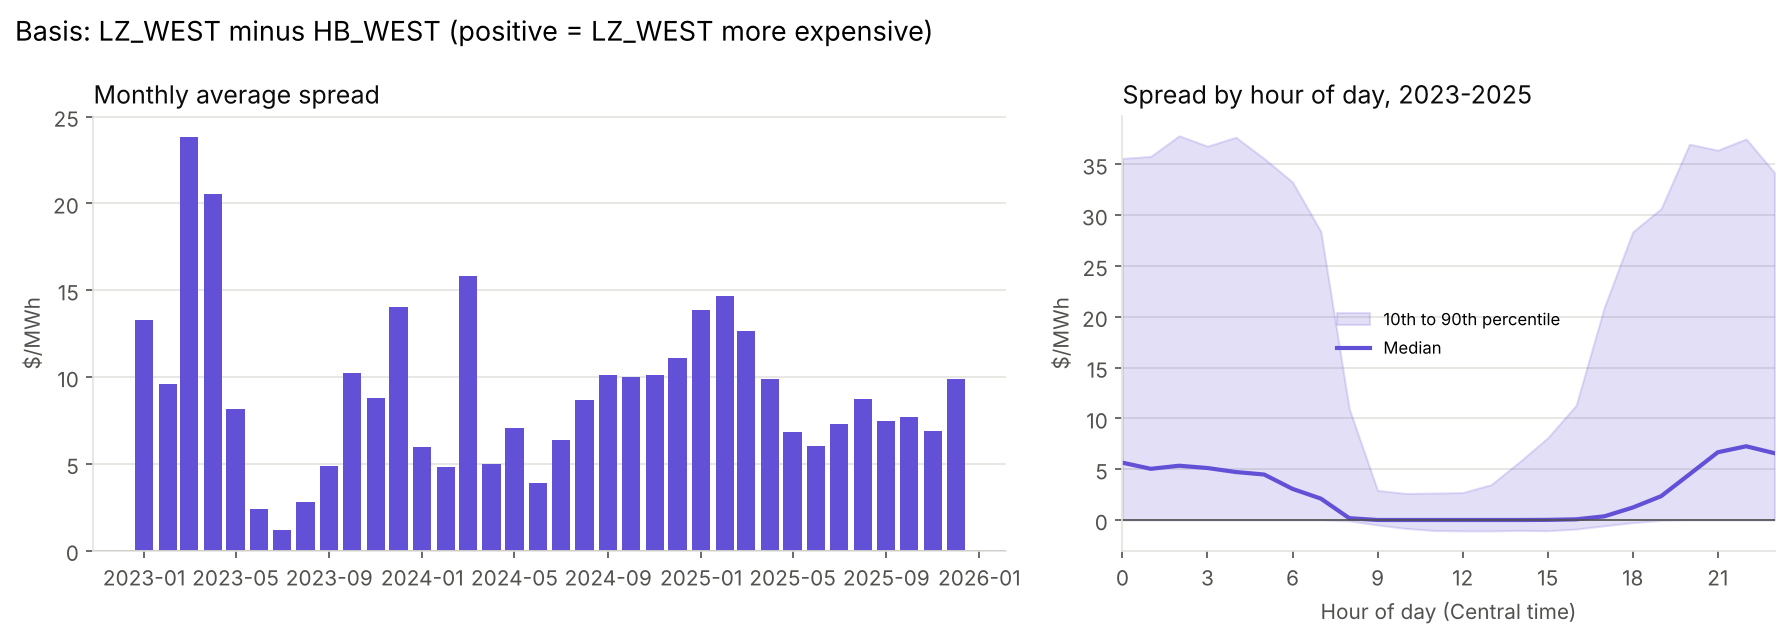

In [8]:
zone_price = data.load_load_zone_prices()
display(risk.basis_summary(zone_price, price))
extra = risk.load_basis_cost(zone_price, price) / 1e6
print("Extra cost of buying 100 MW at LZ_WEST instead of HB_WEST ($M/yr):", extra.round(2).to_dict())
display(Image(plots.plot_basis_risk(zone_price, price)))

LZ_WEST was **more expensive** than the hub in most hours: the median gap is small, but congestion spikes,
mostly at night when West Texas wind floods the lines, push the average to roughly $8-10/MWh.
The VPPA does not cover this gap, so it is a cost the buyer carries on top of the contract.

### 4d. Volume risk: what if it's a calm or cloudy year?

We build a **low-resource year** by scaling every month to the worst capacity factor seen for that
calendar month, keeping the real hourly timing and prices.


SOLAR


,annual_mwh,capacity_factor,annual_settlement,hourly_match
base,"376,385.68",0.21,"42,212.34",0.37
low_resource,"344,282.52",0.20,"505,798.45",0.35



WIND


,annual_mwh,capacity_factor,annual_settlement,hourly_match
base,"572,166.79",0.33,"-4,976,191.31",0.62
low_resource,"519,008.47",0.30,"-4,572,858.69",0.58


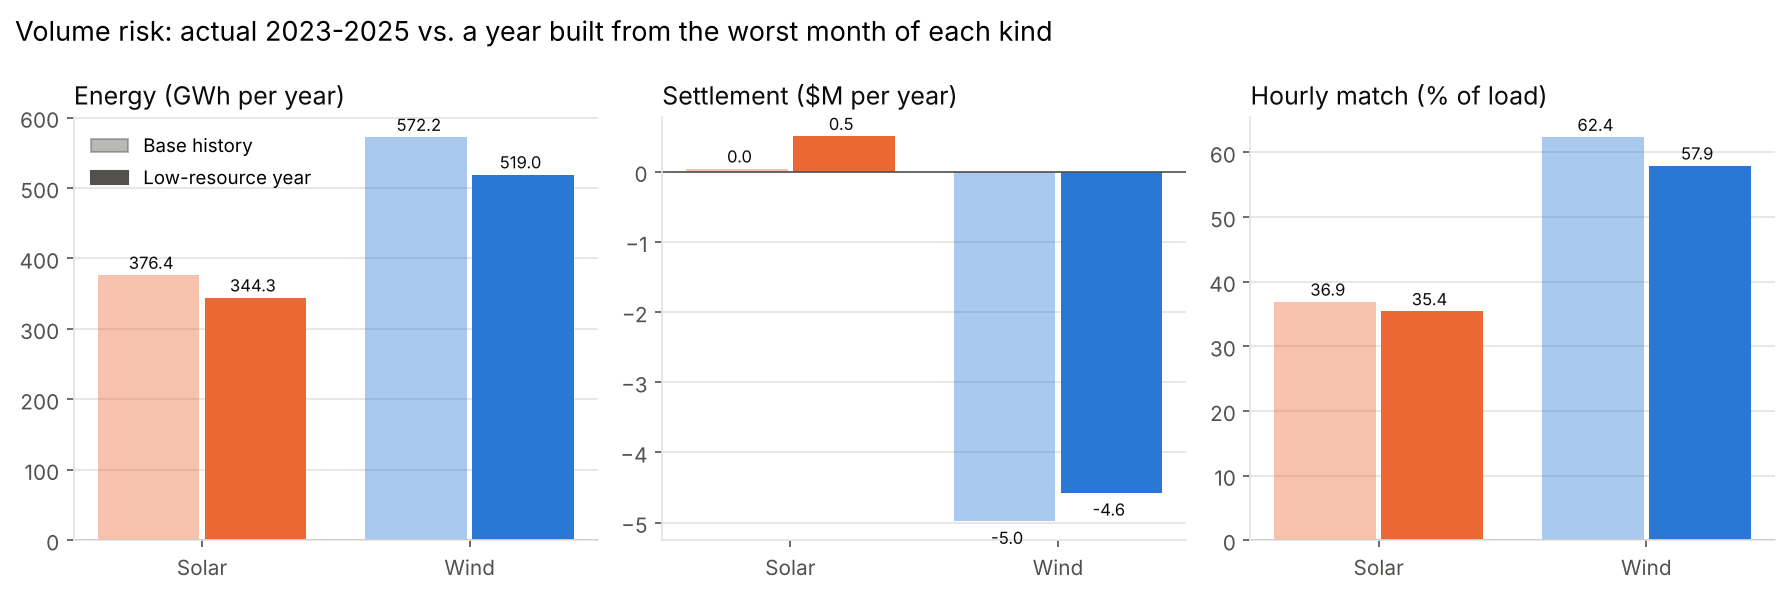

In [9]:
for col, mw in (("solar_mw", config.SOLAR_MW), ("wind_mw", config.WIND_MW)):
    print(f"\n{col[:-3].upper()}")
    display(risk.volume_scenarios(price, gen[col], mw, STRIKE))
display(Image(plots.plot_volume_risk(price, gen, STRIKE)))

Counter-intuitive: when the contract is "out of the money" (prices mostly below strike), **less**
output means **smaller** payments, so a bad wind year can look better financially. It is still worse
for the buyer's clean-energy goal (fewer RECs, lower hourly match) and weakens the hedge.

## 5. Monte Carlo: how bad could a bad year be?

Three years is too few to estimate a 1-in-20 bad year, so we build **10,000 plausible years** from real
pieces of history with a **two-step (nested) bootstrap**:

1. For each month, pick which real year's version to use (e.g. August 2023, 2024 or 2025). This keeps
   that month's regime: heat wave or not, gas price level, windy or calm.
2. Fill the month with real days drawn at random, with replacement, from that historical month.
   Each day keeps its 24 hourly prices and outputs **together**, so their real relationship is preserved.

A first version drew days from all years mixed together; it made every year look average, and the
real 2024 fell *outside* the simulated range. Keeping each month's regime fixed solved that.

**Definitions** (buyer's view, $ per year):
- *Expected value:* average simulated annual settlement.
- *5th percentile:* a 1-in-20 bad year.
- *Cash flow at risk (CFaR, 95%):* expected value − 5th percentile.
- *VaR (95%, 1 month):* average month − 5th percentile month; a short-horizon, trading-style number.

,expected_value_$M,p5_annual_$M,cfar_95_$M,expected_shortfall_$M,p95_annual_$M,var_95_1m_$M,prob_net_payment,hourly_match
solar,0.05,-5.58,5.62,-5.82,9.66,0.75,0.58,0.37
wind,-4.99,-8.25,3.26,-8.78,-0.47,0.96,0.97,0.62


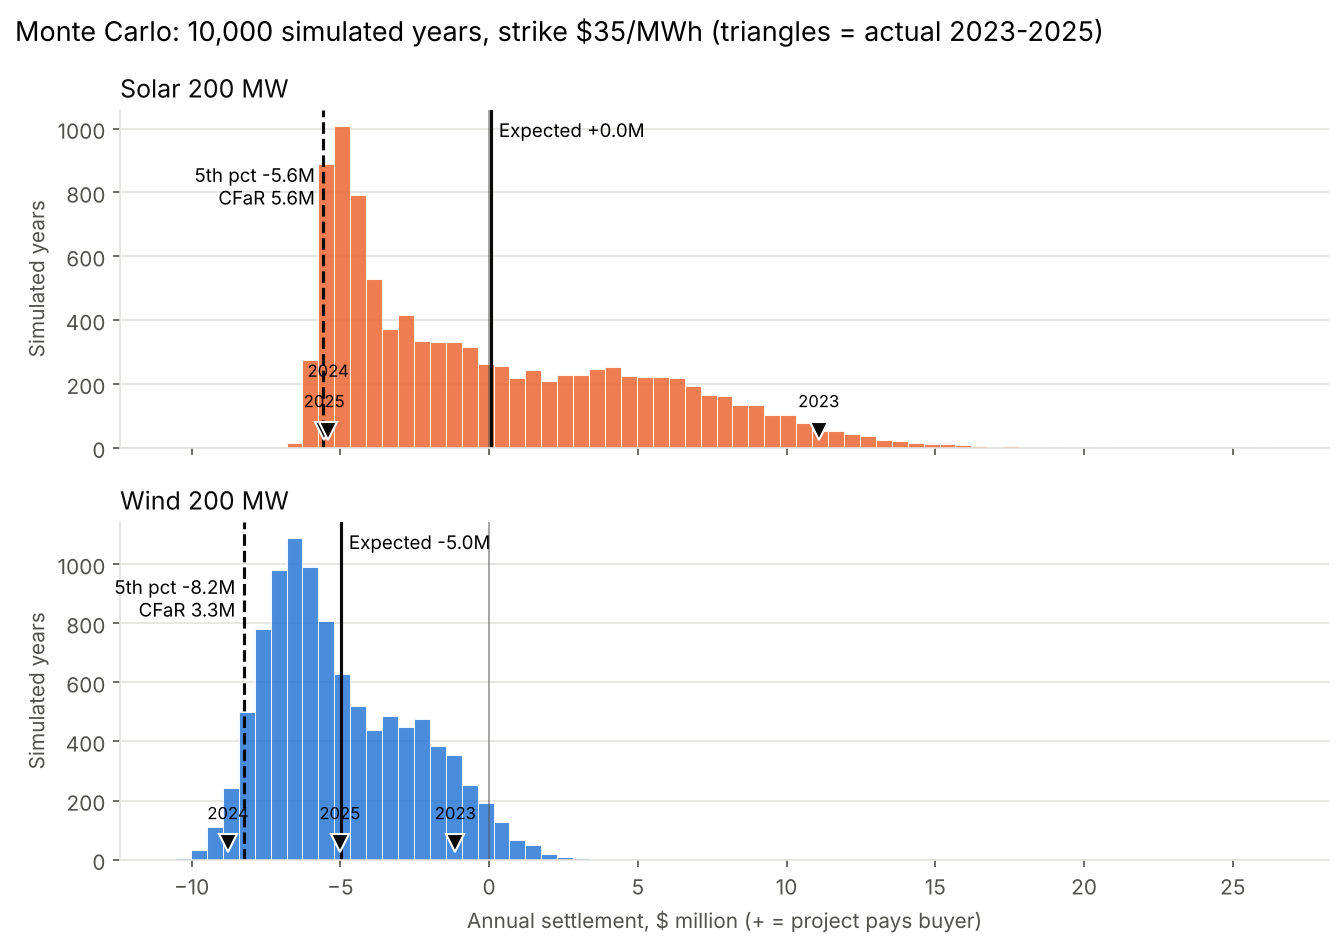

In [10]:
mc_summary, mc_annual = montecarlo.run(price, gen, STRIKE, n_years=10_000, seed=42)
actual = {name: settlement.summarize_settlement(h, "YS")["settlement"].set_axis(h.index.year.unique())
          for name, h in results.items()}
money = ["expected_value", "p5_annual", "cfar_95", "expected_shortfall", "p95_annual", "var_95_1m"]
display((mc_summary[money] / 1e6).add_suffix("_$M").join(mc_summary[["prob_net_payment", "hourly_match"]]))
display(Image(plots.plot_monte_carlo(mc_annual, mc_summary, actual, STRIKE)))

Solar is lopsided: most years cost a little, and occasional heat-wave years pay a lot, so its expected
value is near zero with **wide** uncertainty. Wind is **predictable but reliably costly**.
The triangles (actual 2023-2025) all fall inside the simulated range.

*Limitations:* only three versions of each month exist, months are drawn independently (no multi-month
streaks), and prices predate ERCOT's December 2025 market redesign (RTC+B). Treat CFaR as a **floor**.

## 6. Portfolio: solar, wind, a blend, or solar + battery?

Each option is **sized to produce 100% of the data center's annual use** (size = load ÷ capacity factor),
so they all deliver the same energy and differ only in *when* it arrives.

The battery (half the solar MW, 4 hours, 85% round trip) charges only from solar above the load
and discharges into shortfalls, mostly in the evening.

Generation MW needed for 100% annual match: {'solar': 465, 'wind': 306, 'blend': 369, 'solar_battery': 494}


,expected_value_per_mwh,expected_value_$M,cfar_95_$M,p5_annual_$M,prob_net_payment,annual_mwh,hourly_match,capture_price
solar,0.13,0.11,13.09,-12.98,0.58,"875,093.69",0.44,35.11
wind,-8.73,-7.65,4.99,-12.63,0.97,"875,511.19",0.77,26.30
blend,-5.22,-4.57,7.94,-12.51,0.73,"875,345.52",0.80,29.80
solar_battery,8.21,7.19,14.41,-7.22,0.42,"875,388.47",0.79,43.20


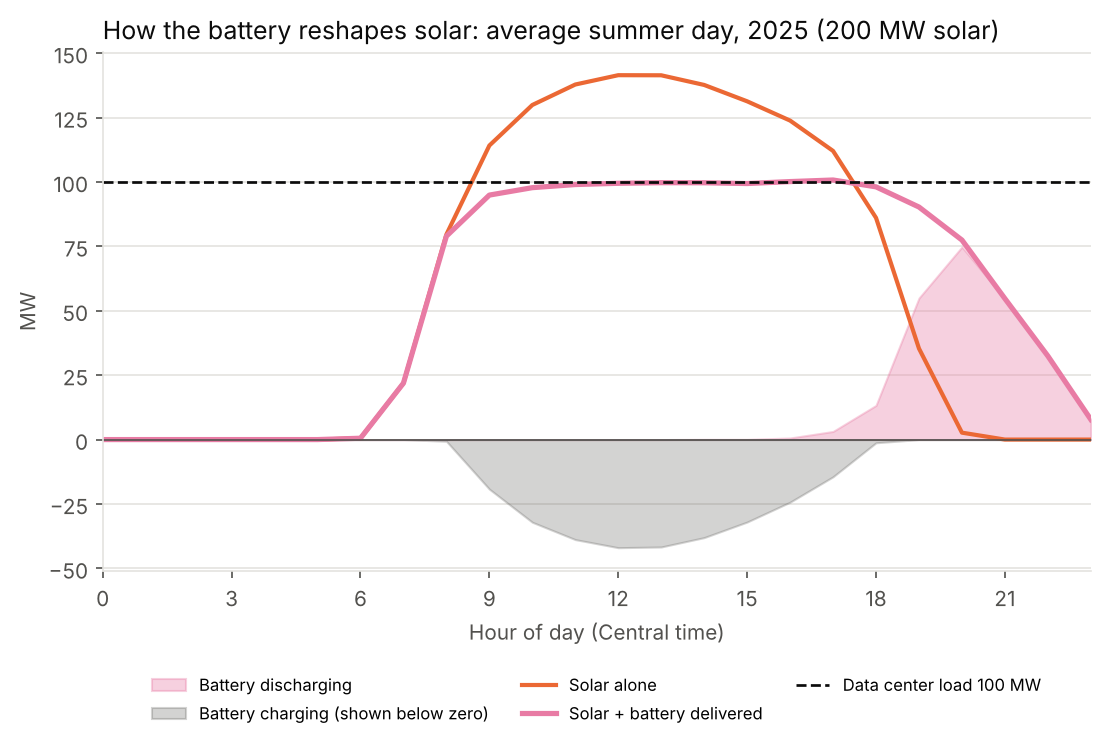

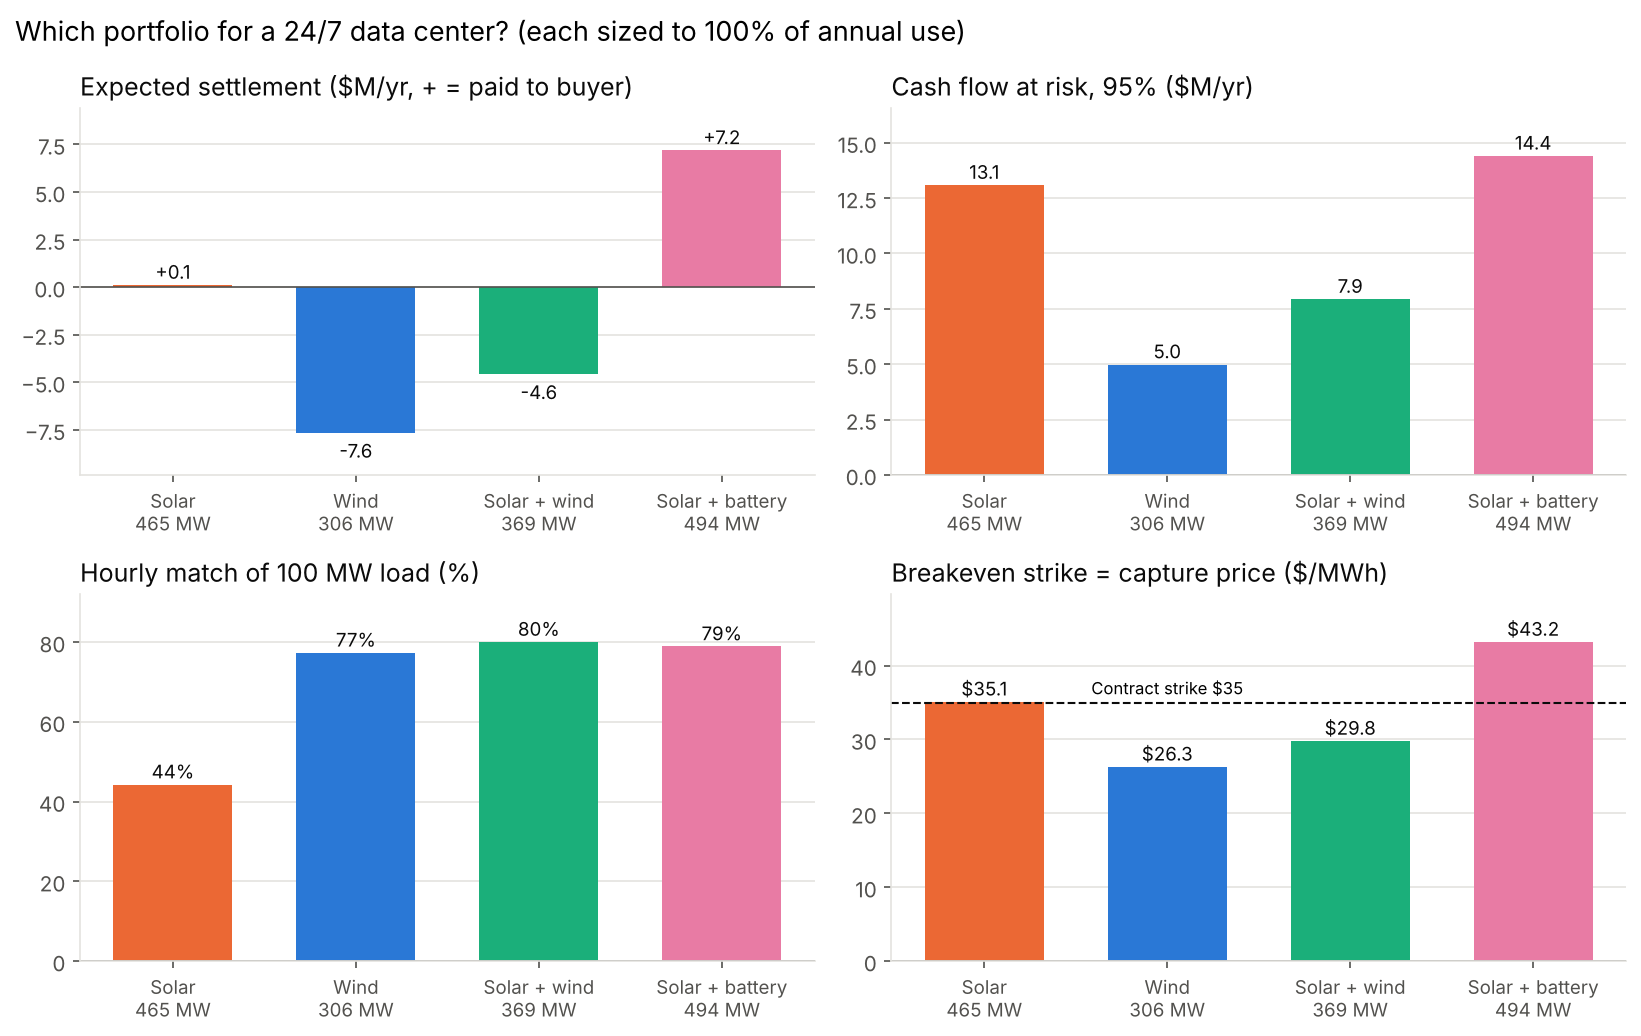

In [11]:
sizes = portfolio.size_for_annual_match(gen)
port = portfolio.build_portfolios(gen, sizes)
port_summary, port_annual = montecarlo.run(price, port, STRIKE)
table = portfolio.compare(price, port, port_summary)
print("Generation MW needed for 100% annual match:", {k: round(v) for k, v in sizes.items()})
show = table.copy()
for c in ("expected_value", "cfar_95", "p5_annual"):
    show[c] = show[c] / 1e6
display(show.rename(columns={"expected_value": "expected_value_$M", "cfar_95": "cfar_95_$M",
                             "p5_annual": "p5_annual_$M"}))
display(Image(plots.plot_battery_day(gen["solar_mw"], portfolio.add_battery(gen["solar_mw"]))))
display(Image(plots.plot_portfolio_comparison(table, sizes, "(each sized to 100% of annual use)")))

## 7. Hedge effectiveness: does the VPPA steady the power bill?

A hedge is judged by whether it makes the buyer's **total** power cost more stable, not by whether
the contract itself makes money. We compare:

- **No VPPA:** the data center buys 100 MW every hour at the HB_WEST price.
- **With a VPPA:** the same purchases, minus what the VPPA pays out (or plus what it costs):

$$\text{net cost} = \text{load} \times \text{price} - \text{VPPA settlement}$$

*Key assumption:* the data center is exposed to the hub price. If it already had a fixed-price retail
contract, it would have no price risk to hedge and the VPPA would **add** risk.

,mean_cost_$M,std_cost_$M,cost_p95_$M,worst_case_saving_$M,hedge_premium_$M,std_reduction
no_vppa,32.05,6.64,44.36,0.00,0.00,0.00
solar,31.94,5.63,38.81,5.55,-0.11,0.15
wind,39.69,3.14,45.53,-1.17,7.65,0.53
blend,36.62,0.99,38.18,6.17,4.57,0.85
solar_battery,24.86,6.85,32.43,11.93,-7.19,-0.03


Actual annual cost ($M) with each option:


,no_vppa,solar,wind,blend,solar_battery
year,,,,,
2023,43.31,17.53,45.05,34.13,9.80
2024,24.11,36.70,37.55,37.21,30.83
2025,28.80,41.70,36.48,38.55,34.05


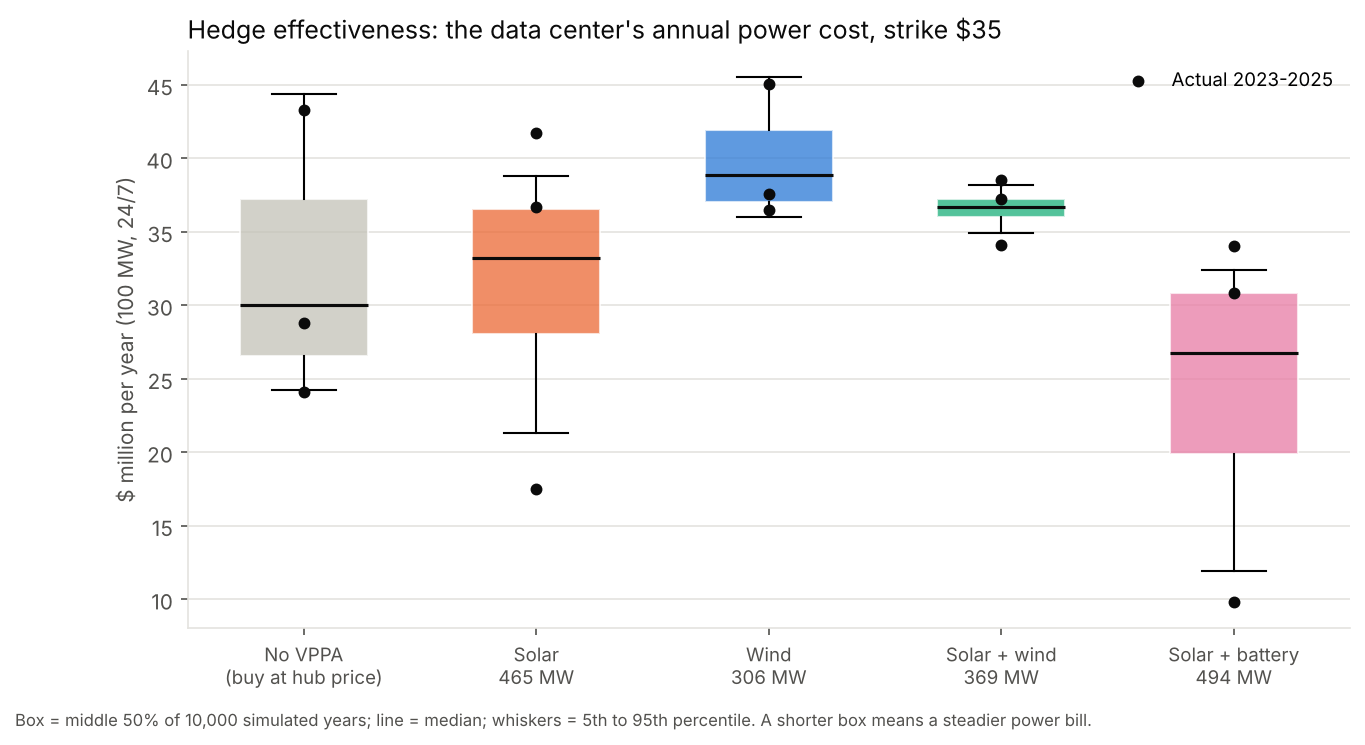

In [12]:
hedge = risk.hedge_effectiveness(port_annual)
money_cols = ["mean_cost", "std_cost", "cost_p95", "worst_case_saving", "hedge_premium"]
display((hedge[money_cols] / 1e6).add_suffix("_$M").join(hedge["std_reduction"]))
hist_annual = risk.annual_costs(price, port, STRIKE)
print("Actual annual cost ($M) with each option:")
display(risk.net_costs(hist_annual) / 1e6)
display(Image(plots.plot_hedge_effectiveness(port_annual, hist_annual, sizes, STRIKE)))

**More realistic version: the data center pays its load zone (LZ_WEST), while the VPPA still settles at HB_WEST.**

In [13]:
_, port_annual_lz = montecarlo.run(price, port, STRIKE, load_price=zone_price)
hedge_lz = risk.hedge_effectiveness(port_annual_lz)
display((hedge_lz[money_cols] / 1e6).add_suffix("_$M").join(hedge_lz["std_reduction"]))

,mean_cost_$M,std_cost_$M,cost_p95_$M,worst_case_saving_$M,hedge_premium_$M,std_reduction
no_vppa,40.12,6.47,52.12,0.00,0.00,0.00
solar,40.01,5.95,47.48,4.64,-0.11,0.08
wind,47.77,3.04,53.41,-1.29,7.65,0.53
blend,44.69,1.45,47.04,5.08,4.57,0.78
solar_battery,32.93,7.17,41.32,10.80,-7.19,-0.11


Buying at the load zone raises every bill by about $8M a year, and the blend now removes somewhat less of
the swing, because the VPPA tracks the hub while the bill follows the load zone. That gap is the
buyer-side basis risk, and no option here hedges it.

**Reading this:** the **solar + wind blend** removes most of the year-to-year swing in the power bill,
at the cost of a higher average bill at this strike: the classic insurance trade-off. **Wind alone**
steadies the bill less and costs more. **Solar + battery** barely steadies it at all: it delivers so much
energy into scarcity hours that it *over-hedges*, behaving more like a bet on price spikes than insurance.

## Findings

*Draft - to be rewritten in the author's own words.*

- **At a $35 strike, a solar + wind VPPA is a strong hedge but not a cheap one:** it removes most of
  the year-to-year swing in the data center's power bill and gives the best hourly match, in exchange
  for a higher average cost, because West Texas prices mostly sat below $35. Its breakeven strike
  (about $30/MWh) is the number to negotiate toward.
- **Solar alone** is cheapest on average at this strike but leaves most hours uncovered and has the
  widest swings.
- **Wind alone** is the most predictable but the most costly at today's West Texas prices.
- **A battery** lifts solar's value per MWh and its hourly match, but as sized here it over-hedges
  scarcity hours and does not steady the bill; it is worth it only if the storage premium is below
  that value uplift. Adding a smaller battery to the blend is the natural next test.
- **The hedge only makes sense if the buyer is exposed to market prices**; with a fixed-price retail
  contract, the VPPA would add risk instead of removing it.
- **Buyer-side basis is large:** buying at LZ_WEST instead of HB_WEST added about $7-9M a year, and the
  hub-settled VPPA does not hedge it. Generator-side basis (node vs. hub) is still pending.

## Limitations and next steps

- Generation is a statewide proxy, not a specific site; generator-side basis is pending node prices.
- Three years of history understates extreme years; no Winter Storm Uri (Feb 2021).
- Prices predate ERCOT's RTC+B market redesign (Dec 2025).
- The battery follows a simple rule and its cost is not modeled.
- Next: add basis risk at a West Texas wind node; extend to **PJM** or **CAISO** for comparison.